In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Main project folder
PROJECT_PATH = '/content/drive/MyDrive/P719_NLP_Sentiment_Analysis'

# Create folders
folders = [
    'dataset',
    'notebooks',
    'visualizations',
    'models',
    'deployment'
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_PATH, folder),
        exist_ok=True
    )

print("Project folders created successfully!")
print(PROJECT_PATH)

Project folders created successfully!
/content/drive/MyDrive/P719_NLP_Sentiment_Analysis


In [3]:
from google.colab import files
import shutil

uploaded = files.upload()

for filename in uploaded.keys():

    shutil.copy(
        filename,
        os.path.join(PROJECT_PATH, 'dataset', filename)
    )

    print(filename, "saved to Google Drive!")

Saving P719-Dataset.xlsx to P719-Dataset.xlsx
P719-Dataset.xlsx saved to Google Drive!


In [4]:
import pandas as pd

DATASET_PATH = os.path.join(
    PROJECT_PATH,
    'dataset',
    'P719-Dataset.xlsx'
)

df = pd.read_excel(DATASET_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1440, 3)


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [5]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
import nltk

# File handling
import os
import warnings

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 200)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
DATASET_PATH = os.path.join(
    PROJECT_PATH,
    'dataset',
    'P719-Dataset.xlsx'
)

df = pd.read_excel(DATASET_PATH)

print("Dataset loaded successfully!")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of Rows: 1440
Number of Columns: 3


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance from Samsung
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u..."
3,A big no from me,1,"1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than a 4MP one.3. Ama..."
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEWS IN YOU TUBE"


In [7]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Column Names:
['title', 'rating', 'body']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


In [8]:
df.describe(include='all')

,title,rating,body
count,1440,1440.000000,1440
unique,1351,NaN,1440
top,Value for money,NaN,Very disappointed with the overall performance from Samsung
freq,16,NaN,1
mean,NaN,3.173611,NaN
std,NaN,1.584453,NaN
min,NaN,1.000000,NaN
25%,NaN,1.000000,NaN
50%,NaN,4.000000,NaN
75%,NaN,5.000000,NaN


In [9]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
title     0
rating    0
body      0
dtype: int64

Total Missing Values: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [11]:
print("Unique Ratings:")
print(sorted(df['rating'].dropna().unique()))

print("\nRating Counts:")
print(df['rating'].value_counts().sort_index())

Unique Ratings:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Rating Counts:
rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


In [12]:
# Create a working copy
df_clean = df.copy()

# Remove exact duplicate records
df_clean.drop_duplicates(inplace=True)

# Remove records with missing essential values
df_clean.dropna(
    subset=['title', 'rating', 'body'],
    inplace=True
)

# Remove leading and trailing whitespace
df_clean['title'] = df_clean['title'].astype(str).str.strip()
df_clean['body'] = df_clean['body'].astype(str).str.strip()

# Remove empty review records
df_clean = df_clean[
    (df_clean['title'] != '') &
    (df_clean['body'] != '')
].copy()

# Validate rating values
df_clean = df_clean[
    df_clean['rating'].isin([1, 2, 3, 4, 5])
].copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1440, 3)
Cleaned Dataset Shape: (1440, 3)


In [13]:
print("FINAL DATA QUALITY REPORT")
print("=" * 40)

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:", df_clean.duplicated().sum())

print("\nRating Distribution:")
print(df_clean['rating'].value_counts().sort_index())

FINAL DATA QUALITY REPORT
Dataset Shape: (1440, 3)

Missing Values:
title     0
rating    0
body      0
dtype: int64

Duplicate Records: 0

Rating Distribution:
rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


In [14]:
CLEANED_DATA_PATH = os.path.join(
    PROJECT_PATH,
    'dataset',
    'P719_Cleaned_Dataset.csv'
)

df_clean.to_csv(
    CLEANED_DATA_PATH,
    index=False
)

print("Cleaned dataset saved successfully!")
print(CLEANED_DATA_PATH)

Cleaned dataset saved successfully!
/content/drive/MyDrive/P719_NLP_Sentiment_Analysis/dataset/P719_Cleaned_Dataset.csv


In [15]:
def assign_sentiment(rating):

    if rating <= 2:
        return 'Negative'

    elif rating == 3:
        return 'Neutral'

    else:
        return 'Positive'


df_clean['sentiment'] = df_clean['rating'].apply(assign_sentiment)

# Display sample records
df_clean[['title', 'rating', 'sentiment', 'body']].head(10)

,title,rating,sentiment,body
0,Horrible product,1,Negative,Very disappointed with the overall performance from Samsung
1,Camera quality is not like 48 megapixel,3,Neutral,Camera quality is low
2,Overall,4,Positive,"Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u..."
3,A big no from me,1,Negative,"1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than a 4MP one.3. Ama..."
4,Put your money somewhere else,1,Negative,"Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEWS IN YOU TUBE"
5,Too much lagging and slow,1,Negative,I will never purchase Samsung phones. Phone is lagging too much and slow. Waste of hard earning money.
6,Worst samsung mobile ever,1,Negative,This is worst samsung mobile I have seen from samsung. It's sceen quality and colors are trash. Even a old 5000 rs phone can beat it's quality. Please never ever buy this product.
7,कैसा दिखाते है उसका 10 % भी नही,1,Negative,मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बताया और क्लियरिटी 5 मेगा पिक्सल का भी नही है ।मोबाइल भी पुराना सा दिखता है ।इसको नही खरीदे
8,Slow performance,1,Negative,The phone hangs a lot and is very slow. I received a replacement which continues to hang
9,Don’t buy from Amazon.,1,Negative,Very poor quality camera .Found box seal damage still Amazon not taking it back.waste of money.Phone very slow.Don’t buy from Amazon.Now Amazon started cheating customers to make profits.


In [16]:
sentiment_counts = df_clean['sentiment'].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

print("\nSentiment Percentage:")

sentiment_percentage = (
    df_clean['sentiment'].value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

Sentiment Distribution:
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64

Sentiment Percentage:
sentiment
Positive    50.62
Negative    35.56
Neutral     13.82
Name: proportion, dtype: float64


In [17]:
rating_counts = df_clean['rating'].value_counts().sort_index()

print(rating_counts)

rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


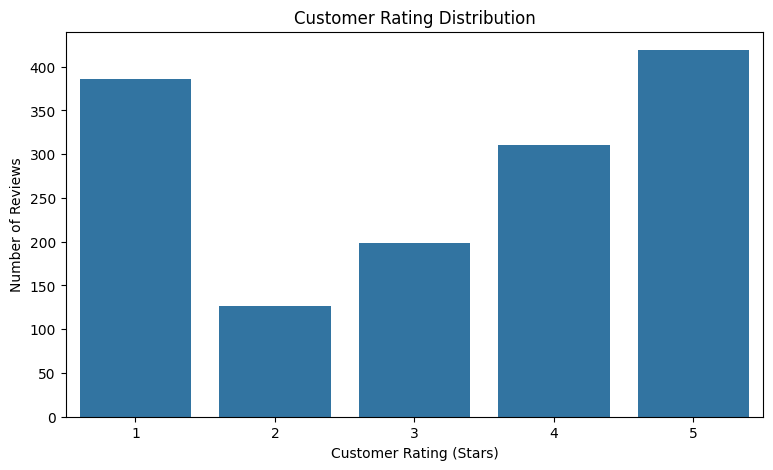

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='rating',
    order=[1, 2, 3, 4, 5]
)

plt.title('Customer Rating Distribution')
plt.xlabel('Customer Rating (Stars)')
plt.ylabel('Number of Reviews')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'rating_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

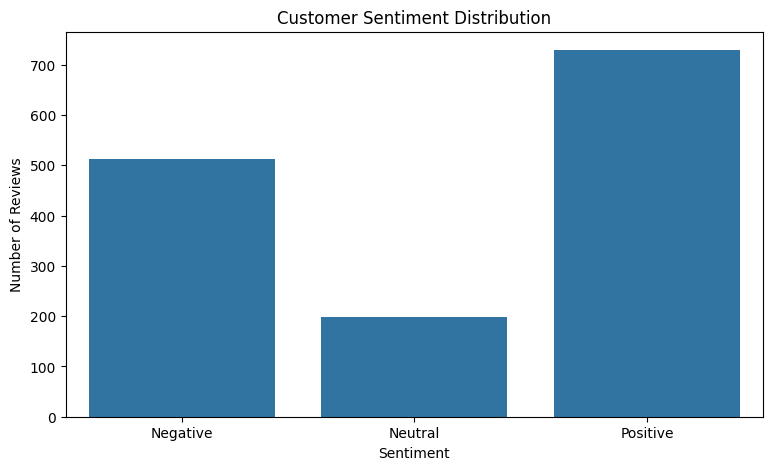

In [19]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='sentiment',
    order=['Negative', 'Neutral', 'Positive']
)

plt.title('Customer Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'sentiment_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [20]:
# Calculate character count
df_clean['character_count'] = df_clean['body'].astype(str).apply(len)

# Calculate word count
df_clean['word_count'] = df_clean['body'].astype(str).apply(
    lambda text: len(text.split())
)

# Statistical summary
df_clean[['character_count', 'word_count']].describe().round(2)

,character_count,word_count
count,1440.00,1440.00
mean,302.11,52.89
std,225.73,39.35
min,4.00,1.00
25%,170.00,29.00
50%,246.00,43.00
75%,359.00,63.25
max,2490.00,385.00


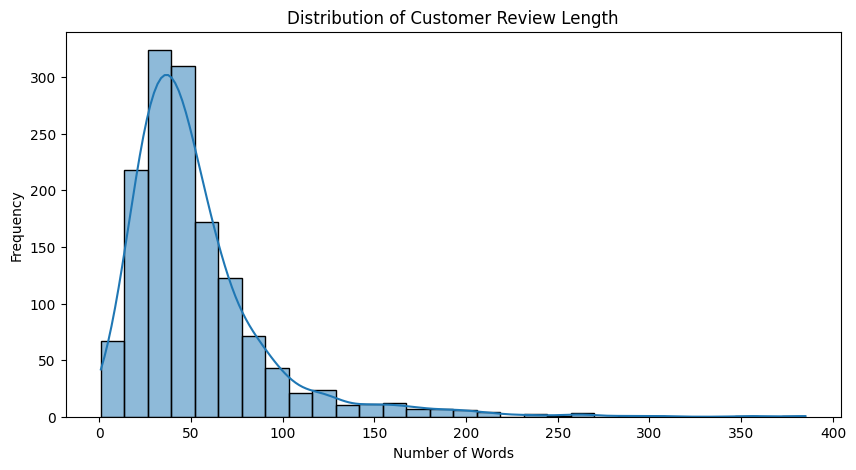

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='word_count',
    bins=30,
    kde=True
)

plt.title('Distribution of Customer Review Length')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'review_length_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

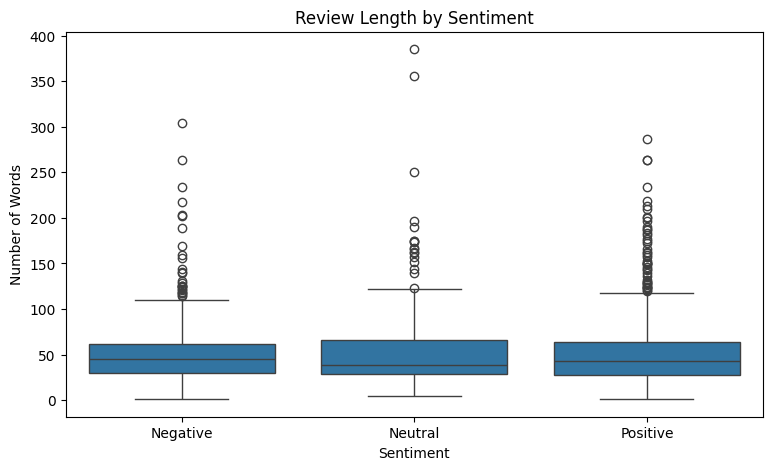

In [22]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='sentiment',
    y='word_count',
    order=['Negative', 'Neutral', 'Positive']
)

plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Words')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'review_length_by_sentiment.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [23]:
sentiment_rating = pd.crosstab(
    df_clean['rating'],
    df_clean['sentiment']
)

sentiment_rating

sentiment,Negative,Neutral,Positive
rating,,,
1,386,0,0
2,126,0,0
3,0,199,0
4,0,0,310
5,0,0,419


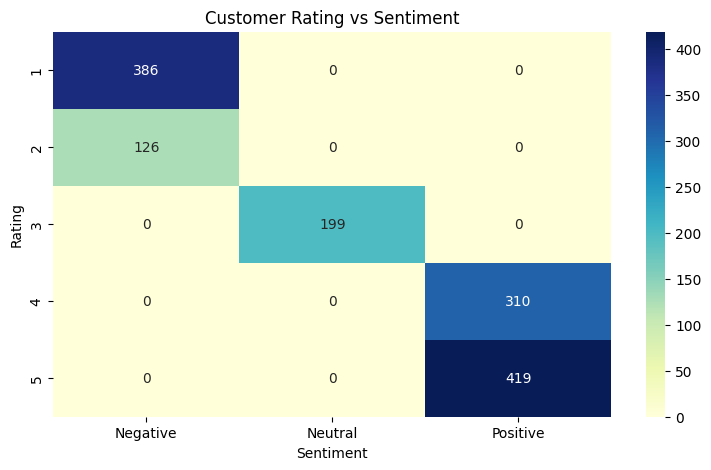

In [24]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    sentiment_rating,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Customer Rating vs Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Rating')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'sentiment_rating_heatmap.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [25]:
EDA_DATA_PATH = os.path.join(
    PROJECT_PATH,
    'dataset',
    'P719_EDA_Dataset.csv'
)

df_clean.to_csv(EDA_DATA_PATH, index=False)

print("EDA dataset saved successfully!")

EDA dataset saved successfully!


In [26]:
df_clean['full_review'] = (
    df_clean['title'].astype(str) + ' ' +
    df_clean['body'].astype(str)
)

df_clean[['title', 'body', 'full_review']].head()

,title,body,full_review
0,Horrible product,Very disappointed with the overall performance from Samsung,Horrible product Very disappointed with the overall performance from Samsung
1,Camera quality is not like 48 megapixel,Camera quality is low,Camera quality is not like 48 megapixel Camera quality is low
2,Overall,"Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u...","Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm ..."
3,A big no from me,"1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than a 4MP one.3. Ama...","A big no from me 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than..."
4,Put your money somewhere else,"Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEWS IN YOU TUBE","Put your money somewhere else Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEW..."


In [27]:
import re

def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^\w\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df_clean['clean_review'] = (
    df_clean['full_review'].apply(clean_text)
)

df_clean[['full_review', 'clean_review']].head()

,full_review,clean_review
0,Horrible product Very disappointed with the overall performance from Samsung,horrible product very disappointed with the overall performance from samsung
1,Camera quality is not like 48 megapixel Camera quality is low,camera quality is not like megapixel camera quality is low
2,"Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm ...",overall got the mobile on the launch date battery must be appreciatedcamera is just averagemobile performance is above averagehz refresh rate if u r buying the mobile for this feature then i m afr...
3,"A big no from me 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than...",a big no from me it doesn t work with ghz wifi frequency ghz is very old school camera quality is pathetic both front and back forget about mp pictures are all blur poorer than a mp one amazon did...
4,"Put your money somewhere else Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEW...",put your money somewhere else not worth buying faulty software poor display quality single band wifi doesn t support ghz wifi band gyro sensor missing and many more dont go by paid reviews in you ...


In [28]:
from collections import Counter

all_words = ' '.join(
    df_clean['clean_review']
).split()

word_counts = Counter(all_words)

top_words = word_counts.most_common(20)

top_words

[('is', 3170),
 ('the', 2293),
 ('phone', 1881),
 ('and', 1758),
 ('it', 1618),
 ('this', 1542),
 ('good', 1479),
 ('for', 1459),
 ('i', 1451),
 ('not', 1393),
 ('to', 1341),
 ('a', 1225),
 ('camera', 1082),
 ('in', 1079),
 ('battery', 896),
 ('of', 849),
 ('samsung', 806),
 ('with', 774),
 ('but', 751),
 ('very', 739)]

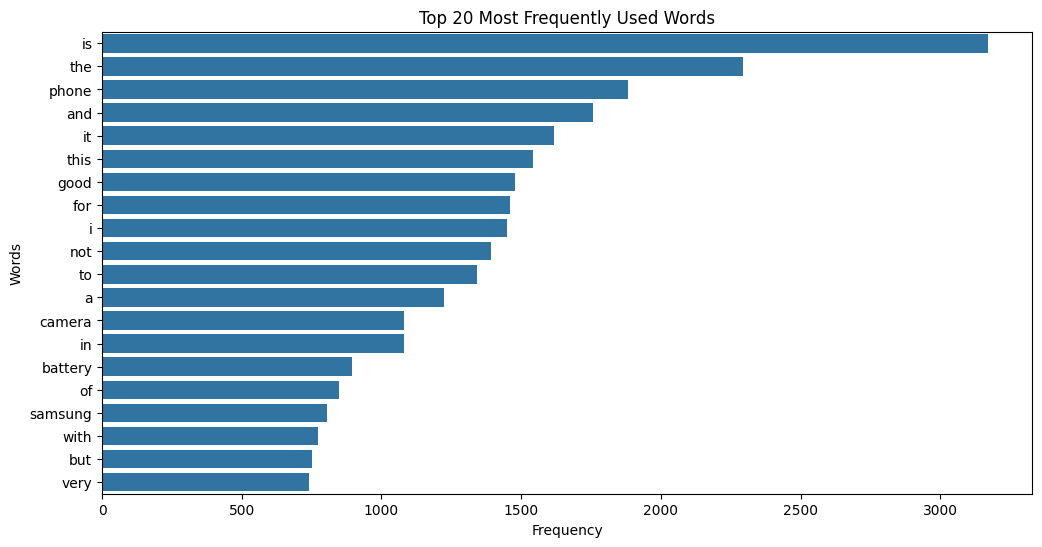

In [29]:
words_df = pd.DataFrame(
    top_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Most Frequently Used Words')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'top_20_words.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [30]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve sentiment-related negation words
negation_words = {'no', 'nor', 'not', 'never'}

stop_words = stop_words - negation_words

print("Total stopwords:", len(stop_words))

Total stopwords: 195


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [31]:
def remove_stopwords(text):

    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)


df_clean['filtered_review'] = (
    df_clean['clean_review'].apply(remove_stopwords)
)

df_clean[['clean_review', 'filtered_review']].head()

,clean_review,filtered_review
0,horrible product very disappointed with the overall performance from samsung,horrible product disappointed overall performance samsung
1,camera quality is not like megapixel camera quality is low,camera quality not like megapixel camera quality low
2,overall got the mobile on the launch date battery must be appreciatedcamera is just averagemobile performance is above averagehz refresh rate if u r buying the mobile for this feature then i m afr...,overall got mobile launch date battery must appreciatedcamera averagemobile performance averagehz refresh rate u r buying mobile feature afraid u may get disappointed normal usb cable small length...
3,a big no from me it doesn t work with ghz wifi frequency ghz is very old school camera quality is pathetic both front and back forget about mp pictures are all blur poorer than a mp one amazon did...,big no work ghz wifi frequency ghz old school camera quality pathetic front back forget mp pictures blur poorer mp one amazon allow write review sold stock something fishy no return policy live ph...
4,put your money somewhere else not worth buying faulty software poor display quality single band wifi doesn t support ghz wifi band gyro sensor missing and many more dont go by paid reviews in you ...,put money somewhere else not worth buying faulty software poor display quality single band wifi support ghz wifi band gyro sensor missing many dont go paid reviews tube


In [32]:
filtered_words = ' '.join(
    df_clean['filtered_review']
).split()

filtered_counts = Counter(filtered_words)

top_filtered_words = filtered_counts.most_common(20)

top_filtered_words

[('phone', 1881),
 ('good', 1479),
 ('not', 1393),
 ('camera', 1082),
 ('battery', 896),
 ('samsung', 806),
 ('quality', 722),
 ('mobile', 620),
 ('price', 457),
 ('product', 432),
 ('buy', 345),
 ('display', 330),
 ('also', 322),
 ('life', 319),
 ('no', 301),
 ('like', 290),
 ('screen', 271),
 ('use', 270),
 ('one', 266),
 ('better', 265)]

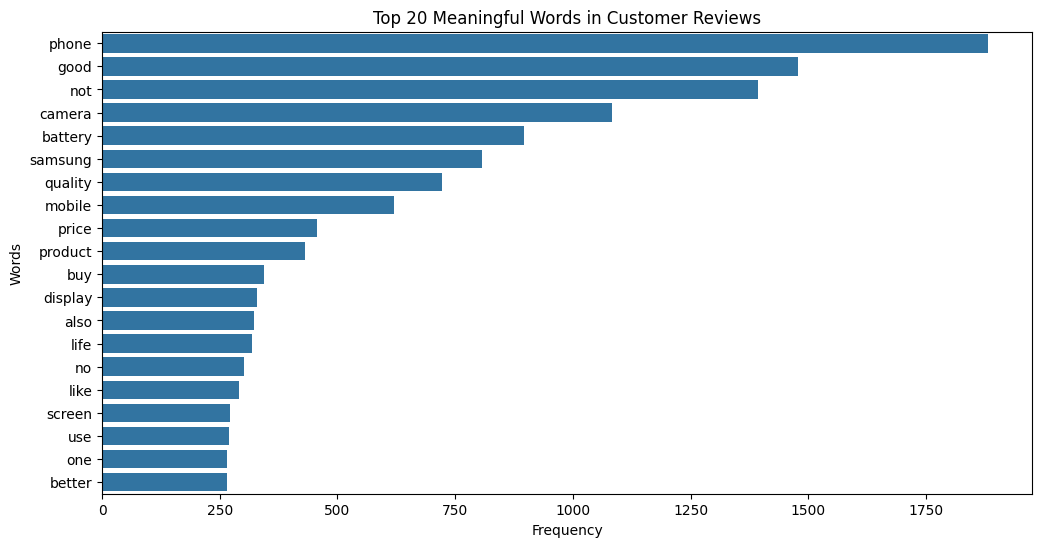

In [33]:
filtered_df = pd.DataFrame(
    top_filtered_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=filtered_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 20 Meaningful Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'top_20_meaningful_words.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [34]:
for sentiment in ['Positive', 'Negative', 'Neutral']:

    sentiment_text = ' '.join(
        df_clean.loc[
            df_clean['sentiment'] == sentiment,
            'filtered_review'
        ]
    )

    words = sentiment_text.split()

    word_frequency = Counter(words)

    print(f"\nTop 15 Words in {sentiment} Reviews:")

    print(word_frequency.most_common(15))


Top 15 Words in Positive Reviews:
[('good', 1076), ('phone', 980), ('battery', 599), ('camera', 599), ('not', 460), ('quality', 348), ('price', 338), ('samsung', 327), ('life', 229), ('mobile', 224), ('best', 214), ('budget', 213), ('great', 208), ('product', 182), ('use', 172)]

Top 15 Words in Negative Reviews:
[('phone', 642), ('not', 636), ('samsung', 377), ('camera', 299), ('mobile', 291), ('quality', 251), ('product', 224), ('buy', 217), ('worst', 198), ('good', 190), ('amazon', 187), ('battery', 175), ('no', 132), ('poor', 130), ('bad', 120)]

Top 15 Words in Neutral Reviews:
[('not', 297), ('phone', 259), ('good', 213), ('camera', 184), ('quality', 123), ('battery', 122), ('mobile', 105), ('samsung', 102), ('average', 75), ('price', 61), ('better', 52), ('heavy', 49), ('display', 45), ('screen', 45), ('also', 45)]


In [35]:
!pip install wordcloud

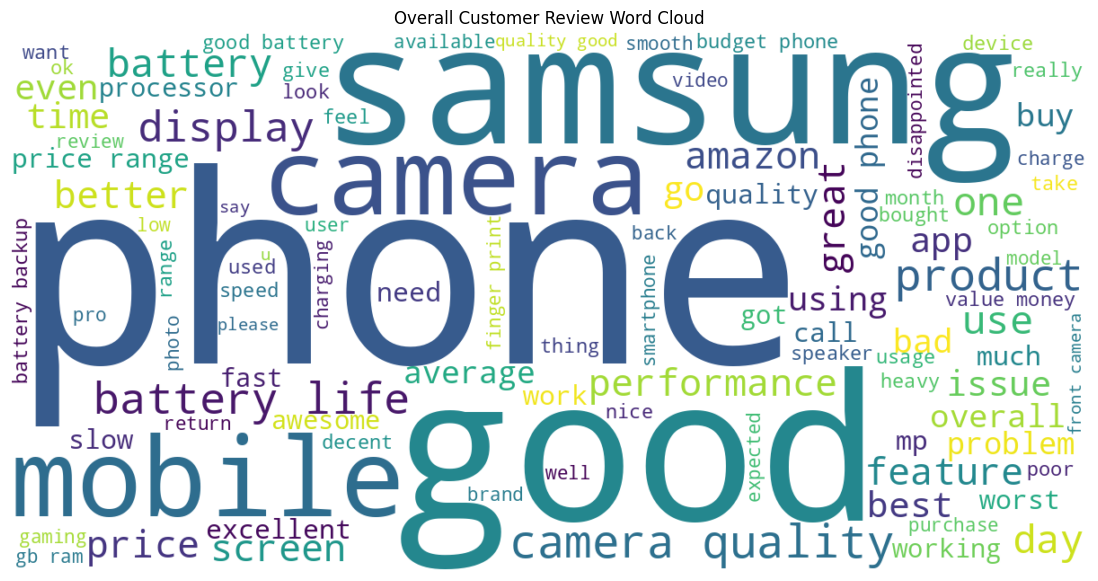

In [36]:
from wordcloud import WordCloud

all_text = ' '.join(df_clean['filtered_review'])

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate(all_text)

plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Overall Customer Review Word Cloud')

plt.savefig(
    os.path.join(PROJECT_PATH, 'visualizations', 'overall_wordcloud.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

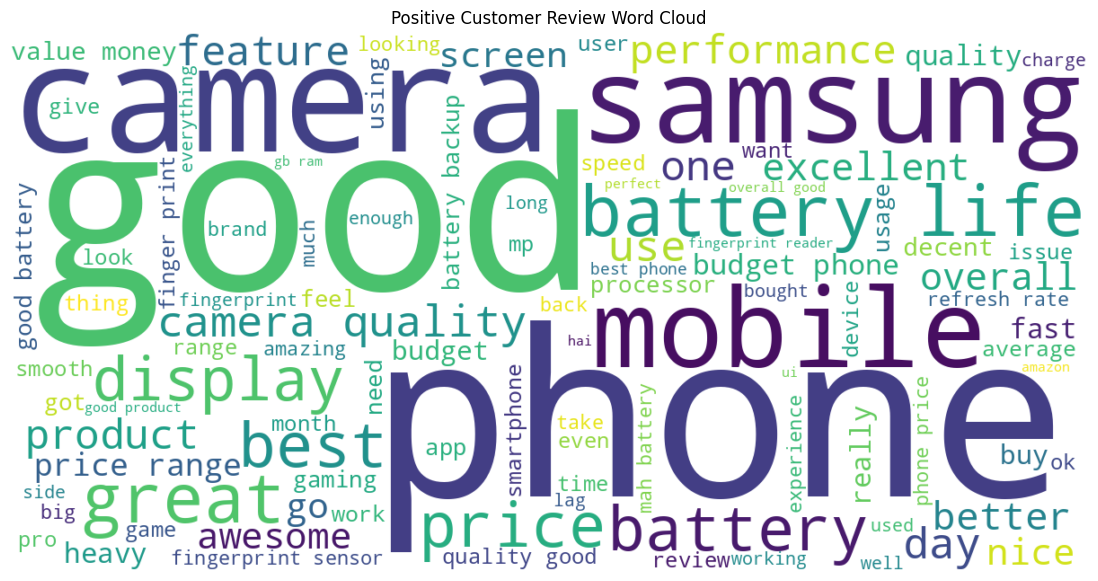

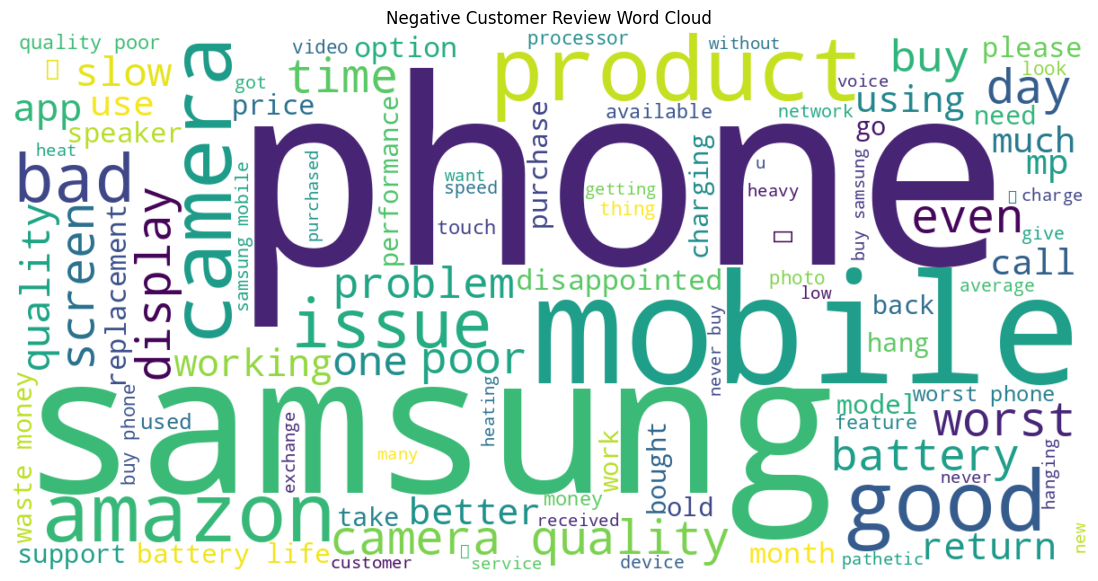

In [37]:
for sentiment in ['Positive', 'Negative']:

    sentiment_text = ' '.join(
        df_clean.loc[
            df_clean['sentiment'] == sentiment,
            'filtered_review'
        ]
    )

    if not sentiment_text.strip():
        print(f"No text available for {sentiment}")
        continue

    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        max_words=100
    ).generate(sentiment_text)

    plt.figure(figsize=(15, 7))

    plt.imshow(wordcloud, interpolation='bilinear')

    plt.axis('off')

    plt.title(f'{sentiment} Customer Review Word Cloud')

    plt.savefig(
        os.path.join(
            PROJECT_PATH,
            'visualizations',
            f'{sentiment.lower()}_wordcloud.png'
        ),
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

In [38]:
EDA_DATA_PATH = os.path.join(
    PROJECT_PATH,
    'dataset',
    'P719_EDA_Dataset.csv'
)

df_clean.to_csv(
    EDA_DATA_PATH,
    index=False
)

print("Updated EDA dataset saved successfully!")

Updated EDA dataset saved successfully!


In [39]:
# Create a separate modeling dataset

df_model = df_clean.copy()

# Combine title and review body
df_model['review_text'] = (
    df_model['title'].astype(str) + ' ' +
    df_model['body'].astype(str)
)

# Keep required columns
df_model = df_model[
    ['review_text', 'rating', 'sentiment']
].copy()

print("Modeling Dataset Shape:", df_model.shape)

df_model.head()

Modeling Dataset Shape: (1440, 3)


,review_text,rating,sentiment
0,Horrible product Very disappointed with the overall performance from Samsung,1,Negative
1,Camera quality is not like 48 megapixel Camera quality is low,3,Neutral
2,"Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm ...",4,Positive
3,"A big no from me 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than...",1,Negative
4,"Put your money somewhere else Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEW...",1,Negative


In [40]:
print("Missing Values:")
print(df_model.isnull().sum())

print("\nEmpty Reviews:")

print(
    df_model['review_text']
    .str.strip()
    .eq('')
    .sum()
)

Missing Values:
review_text    0
rating         0
sentiment      0
dtype: int64

Empty Reviews:
0


In [41]:
df_model['character_count'] = (
    df_model['review_text'].str.len()
)

df_model['word_count'] = (
    df_model['review_text'].str.split().str.len()
)

df_model[['character_count', 'word_count']].describe().round(2)

,character_count,word_count
count,1440.00,1440.00
mean,333.38,58.26
std,229.12,39.90
min,9.00,2.00
25%,198.00,34.00
50%,277.00,49.00
75%,395.00,70.00
max,2536.00,391.00


In [42]:
import re

def preprocess_text(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^\w\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df_model['processed_text'] = (
    df_model['review_text'].apply(preprocess_text)
)

df_model[['review_text', 'processed_text']].head()

,review_text,processed_text
0,Horrible product Very disappointed with the overall performance from Samsung,horrible product very disappointed with the overall performance from samsung
1,Camera quality is not like 48 megapixel Camera quality is low,camera quality is not like megapixel camera quality is low
2,"Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm ...",overall got the mobile on the launch date battery must be appreciatedcamera is just averagemobile performance is above averagehz refresh rate if u r buying the mobile for this feature then i m afr...
3,"A big no from me 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than...",a big no from me it doesn t work with ghz wifi frequency ghz is very old school camera quality is pathetic both front and back forget about mp pictures are all blur poorer than a mp one amazon did...
4,"Put your money somewhere else Not worth buying....faulty software, poor display quality, single band wifi doesn't support 5ghz WIFI band. Gyro sensor missing and many more. DONT GO BY PAID REVIEW...",put your money somewhere else not worth buying faulty software poor display quality single band wifi doesn t support ghz wifi band gyro sensor missing and many more dont go by paid reviews in you ...


In [43]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve important negation words
negation_words = {
    'no', 'nor', 'not', 'never'
}

stop_words = stop_words - negation_words

print("Total Stopwords:", len(stop_words))

Total Stopwords: 195


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [44]:
def remove_stopwords(text):

    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)


df_model['final_text'] = (
    df_model['processed_text'].apply(remove_stopwords)
)

df_model[['processed_text', 'final_text']].head()

,processed_text,final_text
0,horrible product very disappointed with the overall performance from samsung,horrible product disappointed overall performance samsung
1,camera quality is not like megapixel camera quality is low,camera quality not like megapixel camera quality low
2,overall got the mobile on the launch date battery must be appreciatedcamera is just averagemobile performance is above averagehz refresh rate if u r buying the mobile for this feature then i m afr...,overall got mobile launch date battery must appreciatedcamera averagemobile performance averagehz refresh rate u r buying mobile feature afraid u may get disappointed normal usb cable small length...
3,a big no from me it doesn t work with ghz wifi frequency ghz is very old school camera quality is pathetic both front and back forget about mp pictures are all blur poorer than a mp one amazon did...,big no work ghz wifi frequency ghz old school camera quality pathetic front back forget mp pictures blur poorer mp one amazon allow write review sold stock something fishy no return policy live ph...
4,put your money somewhere else not worth buying faulty software poor display quality single band wifi doesn t support ghz wifi band gyro sensor missing and many more dont go by paid reviews in you ...,put money somewhere else not worth buying faulty software poor display quality single band wifi support ghz wifi band gyro sensor missing many dont go paid reviews tube


In [45]:
for i in range(5):

    print("ORIGINAL REVIEW:")
    print(df_model['review_text'].iloc[i])

    print("\nPROCESSED REVIEW:")
    print(df_model['final_text'].iloc[i])

    print("\nSENTIMENT:")
    print(df_model['sentiment'].iloc[i])

    print("-" * 80)

ORIGINAL REVIEW:
Horrible product Very disappointed with the overall performance from Samsung

PROCESSED REVIEW:
horrible product disappointed overall performance samsung

SENTIMENT:
Negative
--------------------------------------------------------------------------------
ORIGINAL REVIEW:
Camera quality is not like 48 megapixel Camera quality is low

PROCESSED REVIEW:
camera quality not like megapixel camera quality low

SENTIMENT:
Neutral
--------------------------------------------------------------------------------
ORIGINAL REVIEW:
Overall Got the mobile on the launch date,Battery must be appreciatedCamera is just averageMobile performance is above average90hz refresh rate? If u r buying the mobile for this feature then I'm afraid u may get disappointed, it's just normal.The USB cable is too small in lengthIt's a good mobile in this budget, there are no returns for this,  only replacement is available, hence choose wisely before buying

PROCESSED REVIEW:
overall got mobile launch d

In [46]:
X = df_model['final_text']

y = df_model['sentiment']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nSentiment Distribution:")
print(y.value_counts())

Input Features Shape: (1440,)
Target Variable Shape: (1440,)

Sentiment Distribution:
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Samples: 1152
Testing Samples: 288

Training Distribution:
sentiment
Positive    583
Negative    410
Neutral     159
Name: count, dtype: int64

Testing Distribution:
sentiment
Positive    146
Negative    102
Neutral      40
Name: count, dtype: int64


In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [49]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit on training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization Completed!")

print("\nTraining Matrix Shape:", X_train_tfidf.shape)

print("\nTesting Matrix Shape:", X_test_tfidf.shape)

print("\nVocabulary Size:", len(tfidf.vocabulary_))

TF-IDF Vectorization Completed!

Training Matrix Shape: (1152, 5000)

Testing Matrix Shape: (288, 5000)

Vocabulary Size: 5000


In [50]:
feature_names = tfidf.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 30 Features:")
print(feature_names[:30])

Total Features: 5000

First 30 Features:
['aap' 'able' 'able hear' 'able return' 'absolute' 'absolutely'
 'absolutely fine' 'accept' 'accept return' 'acceptable' 'access'
 'accessories' 'accha' 'according' 'according price' 'accurate' 'achcha'
 'achha' 'across' 'action' 'action need' 'activated' 'active' 'actual'
 'actually' 'adapter' 'adaptive' 'adaptive brightness' 'adaptive refresh'
 'add']


In [51]:
tfidf_sample = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=feature_names
)

tfidf_sample.iloc[:, :20]

,aap,able,able hear,able return,absolute,absolutely,absolutely fine,accept,accept return,acceptable,access,accessories,accha,according,according price,accurate,achcha,achha,across,action
0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.123532,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [52]:
import joblib

MODEL_PATH = os.path.join(PROJECT_PATH, 'models')

os.makedirs(MODEL_PATH, exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(MODEL_PATH, 'tfidf_vectorizer.pkl')
)

# Save training and testing features
joblib.dump(
    X_train_tfidf,
    os.path.join(MODEL_PATH, 'X_train_tfidf.pkl')
)

joblib.dump(
    X_test_tfidf,
    os.path.join(MODEL_PATH, 'X_test_tfidf.pkl')
)

# Save target variables
joblib.dump(
    y_train,
    os.path.join(MODEL_PATH, 'y_train.pkl')
)

joblib.dump(
    y_test,
    os.path.join(MODEL_PATH, 'y_test.pkl')
)

print("Feature engineering outputs saved successfully!")

Feature engineering outputs saved successfully!


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import os

In [54]:
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training data shape: (1152, 5000)
Testing data shape: (288, 5000)

Training labels:
sentiment
Positive    583
Negative    410
Neutral     159
Name: count, dtype: int64

Testing labels:
sentiment
Positive    146
Negative    102
Neutral      40
Name: count, dtype: int64


In [55]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)

    trained_models[name] = model

    print(f"{name} training completed.")


Training Logistic Regression...
Logistic Regression training completed.

Training Multinomial Naive Bayes...
Multinomial Naive Bayes training completed.

Training Random Forest...
Random Forest training completed.

Training Linear SVM...
Linear SVM training completed.


In [56]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 (Weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 (Macro)",
    ascending=False
).reset_index(drop=True)

print(results_df.round(4))

                     Model  Accuracy  Precision (Macro)  Recall (Macro)  \
0      Logistic Regression    0.7604             0.6538          0.6563   
1               Linear SVM    0.7708             0.6547          0.6450   
2            Random Forest    0.7743             0.7166          0.6100   
3  Multinomial Naive Bayes    0.7708             0.5242          0.5847   

   F1 (Macro)  F1 (Weighted)  
0      0.6543         0.7585  
1      0.6437         0.7573  
2      0.5928         0.7314  
3      0.5486         0.7117  


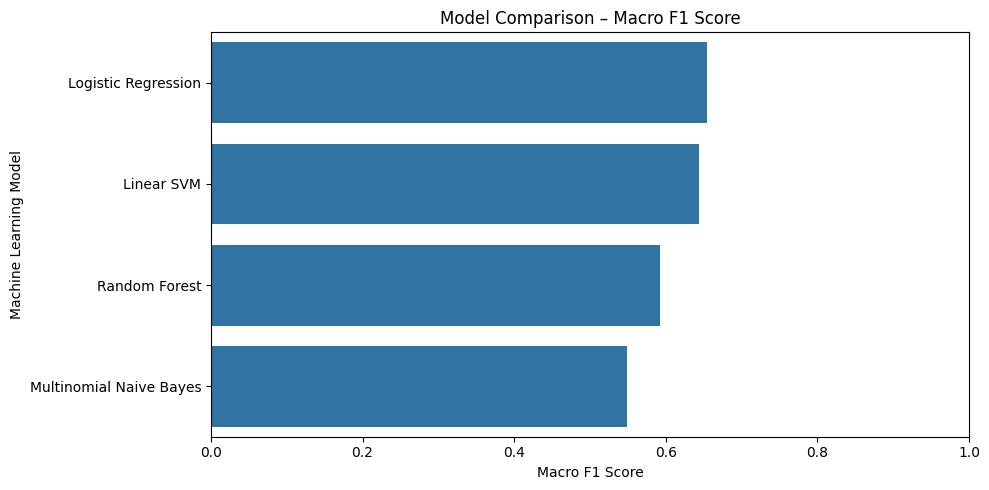

In [57]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="F1 (Macro)",
    y="Model"
)

plt.title("Model Comparison – Macro F1 Score")
plt.xlabel("Macro F1 Score")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "visualizations", "model_comparison.png"),
    dpi=300
)

plt.show()

In [58]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best Macro F1 Score:", results_df.iloc[0]["F1 (Macro)"])

Best Model: Logistic Regression
Best Macro F1 Score: 0.6543190768542881


In [59]:
MODEL_PATH = os.path.join(PROJECT_PATH, "models")

for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        os.path.join(MODEL_PATH, filename)
    )

joblib.dump(
    best_model,
    os.path.join(MODEL_PATH, "best_model.pkl")
)

print("All trained models saved successfully.")

All trained models saved successfully.


In [60]:
y_pred_best = best_model.predict(X_test_tfidf)

print("Selected Model:", best_model_name)
print("Predictions generated successfully.")

Selected Model: Logistic Regression
Predictions generated successfully.


In [61]:
print(classification_report(
    y_test,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.77      0.83      0.80       102
     Neutral       0.32      0.30      0.31        40
    Positive       0.87      0.84      0.85       146

    accuracy                           0.76       288
   macro avg       0.65      0.66      0.65       288
weighted avg       0.76      0.76      0.76       288



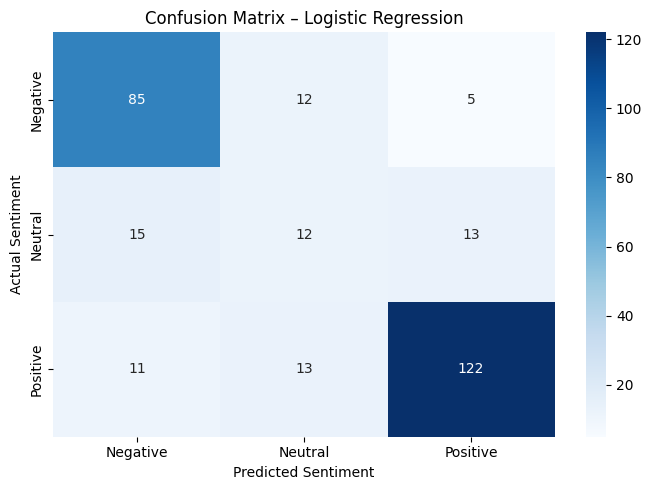

In [62]:
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title(f"Confusion Matrix – {best_model_name}")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "visualizations",
        "best_model_confusion_matrix.png"
    ),
    dpi=300
)

plt.show()

In [63]:
print("Model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print("Macro Precision:", round(
    precision_score(y_test, y_pred_best, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(y_test, y_pred_best, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_best, average="macro", zero_division=0), 4
))

Model: Logistic Regression
Accuracy: 0.7604
Macro Precision: 0.6538
Macro Recall: 0.6563
Macro F1: 0.6543


In [64]:
report = classification_report(
    y_test,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    os.path.join(
        PROJECT_PATH,
        "visualizations",
        "best_model_classification_report.csv"
    )
)

print("Evaluation report saved successfully.")

Evaluation report saved successfully.


In [65]:
print(classification_report(
    y_test,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.77      0.83      0.80       102
     Neutral       0.32      0.30      0.31        40
    Positive       0.87      0.84      0.85       146

    accuracy                           0.76       288
   macro avg       0.65      0.66      0.65       288
weighted avg       0.76      0.76      0.76       288



In [67]:
import joblib
import os

MODEL_PATH = os.path.join(PROJECT_PATH, "models")

vectorizer = joblib.load(
    os.path.join(MODEL_PATH, "tfidf_vectorizer.pkl")
)

print("TF-IDF Vectorizer loaded successfully!")

TF-IDF Vectorizer loaded successfully!


In [68]:
sample_reviews = [
    "The phone camera is excellent and battery backup is amazing.",
    "The product is very disappointing. Battery drains quickly.",
    "The phone is okay, nothing special about it.",
    "Excellent display and smooth performance.",
    "Average product with average features."
]

sample_vectors = vectorizer.transform(sample_reviews)

sample_predictions = best_model.predict(sample_vectors)

for review, prediction in zip(sample_reviews, sample_predictions):
    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print("-" * 60)

Review: The phone camera is excellent and battery backup is amazing.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The product is very disappointing. Battery drains quickly.
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The phone is okay, nothing special about it.
Predicted Sentiment: Neutral
------------------------------------------------------------
Review: Excellent display and smooth performance.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: Average product with average features.
Predicted Sentiment: Neutral
------------------------------------------------------------


In [69]:
misclassified = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_best,
    "Review": X_test.reset_index(drop=True)
})

misclassified = misclassified[
    misclassified["Actual"] != misclassified["Predicted"]
]

print("Total misclassified reviews:", len(misclassified))

display(misclassified.head(15))

Total misclassified reviews: 69


,Actual,Predicted,Review
4,Neutral,Negative,not expecting would expect witha battery size great well okay not great think due size battery phone feels quite heavy camera let say bluntly camera not great okiesh time expect samsung company kn...
13,Positive,Neutral,budget mobile model samsung gb ram rom black bought rsbattery life fingerprint face recognition camera quality sound quality sound quality not expected ram processor cons sound quality not mark so...
31,Negative,Neutral,poor perfofmance heat quickly pathetic phone battery good camera poor performance poor slow cut call notification call ended arrivez stays minutes not see complete keyboard using app absolutely pa...
38,Negative,Neutral,android phone not smart phone delay screen response no compass app runs basic requirement compass app meet front camera resolution low phone gangs time recommend price
43,Positive,Negative,display mediocre price okay display not mark dedicated sd slot expand memory also two sims meets requirement quite happy product
49,Positive,Negative,mahine se toh ekdm shi chal ra hai sab kuch bhandia hai bs ek chiz samsung ki joh shuru se khrb hai ki thoda sa week bar hang ho jata hi sec k lie baki agar mobile ki bat kre toh thoda bhari v hai...
58,Neutral,Negative,phone heavy camera quality not good phone camera not worth quality mentioned device also weight rethink want buy not sure amazon removed return policy better check phone locally shop buy
59,Neutral,Negative,samsung forcing use app remove smasung apps delete samsung forcing use really disappointed hand apple allows delete app even phonebook use third party phonebook
60,Neutral,Positive,good phone performance not smooth liked phone battery last long even tool gb ram version phone little sluggish performance may chipset not great performing daily task one ui great even refresh rat...
62,Negative,Positive,not good advertised contact book not large around contacts yet takes couple seconds load happen previous mobiles even though less powerful device although cameras back portrait mode completely non...


In [70]:
# Count incorrect predictions by actual sentiment

print("Misclassified reviews by actual sentiment:")
print(misclassified["Actual"].value_counts())

print("\nMisclassified reviews by predicted sentiment:")
print(misclassified["Predicted"].value_counts())

Misclassified reviews by actual sentiment:
Actual
Neutral     28
Positive    24
Negative    17
Name: count, dtype: int64

Misclassified reviews by predicted sentiment:
Predicted
Negative    26
Neutral     25
Positive    18
Name: count, dtype: int64


In [71]:
# Display 10 incorrectly classified neutral reviews

neutral_errors = misclassified[
    misclassified["Actual"] == "Neutral"
]

display(
    neutral_errors[["Actual", "Predicted", "Review"]].head(10)
)

,Actual,Predicted,Review
4,Neutral,Negative,not expecting would expect witha battery size great well okay not great think due size battery phone feels quite heavy camera let say bluntly camera not great okiesh time expect samsung company kn...
58,Neutral,Negative,phone heavy camera quality not good phone camera not worth quality mentioned device also weight rethink want buy not sure amazon removed return policy better check phone locally shop buy
59,Neutral,Negative,samsung forcing use app remove smasung apps delete samsung forcing use really disappointed hand apple allows delete app even phonebook use third party phonebook
60,Neutral,Positive,good phone performance not smooth liked phone battery last long even tool gb ram version phone little sluggish performance may chipset not great performing daily task one ui great even refresh rat...
71,Neutral,Positive,budgeted phone ever budgeted phone gb gb storage variant good battery backup awesome took hrs full charge not happy front camera quality awful night no slow motion capturing feature rear camera be...
88,Neutral,Positive,battery life awesome camera pathetic want big battery fast charging go pros awesome battery lifefast chargingspeaker loud crystal clearlike placement figure print sensercons pathetic camera output...
92,Neutral,Negative,not worthy camera quality avarage display quality also bad segment worst mobile dust side mobile box top display open mobile box found much dust mobile screen
98,Neutral,Negative,samsung provide detailed operating manual along customer interface cumbersome one technically efficient operate phone
99,Neutral,Negative,heavy battery battery heavy also used get heated times samsung phones better model
103,Neutral,Positive,fall price lot look details not come back cover screen guard sim slot pin charger wire small display averageoppo vivo displays far better comparativelysoftware bit laggy not ease use software feat...


In [72]:
# Display 10 incorrectly classified negative reviews

negative_errors = misclassified[
    misclassified["Actual"] == "Negative"
]

display(
    negative_errors[["Actual", "Predicted", "Review"]].head(10)
)

,Actual,Predicted,Review
31,Negative,Neutral,poor perfofmance heat quickly pathetic phone battery good camera poor performance poor slow cut call notification call ended arrivez stays minutes not see complete keyboard using app absolutely pa...
38,Negative,Neutral,android phone not smart phone delay screen response no compass app runs basic requirement compass app meet front camera resolution low phone gangs time recommend price
62,Negative,Positive,not good advertised contact book not large around contacts yet takes couple seconds load happen previous mobiles even though less powerful device although cameras back portrait mode completely non...
72,Negative,Positive,good battery good lasts day continue net brwosingfingerprint good expectedcamera quality quite best
73,Negative,Positive,honest review pros good battery life decent camera qualitycons display great processor old age graphic quality little rusty visual quality not sharp vividverdict many best alternatives phones avai...
89,Negative,Neutral,not preferable not preferable mobile games closing heavy size not handy size
105,Negative,Positive,average lot doubts purchase seeing negative reviews lying experience samsung really exciting good battery backup display even though p not bad look screen brightness optimum ram management good da...
114,Negative,Neutral,dissapointed product dissapointed product not value money rs ok positive feedback battery backup camera not good front rear finger print not comfirtable no default call recording option tru call r...
145,Negative,Neutral,good battery battery goodcamera not good zoom images pic taken using zoom details lost hoping samsung release update improve pre installed unwanted apps usable memory less expected may samsung kee...
167,Negative,Neutral,honest opinio con heavy refresh rate not per specifications camera quality not per specifications megapixcel display averagepro battery life brilliant voic quality ok


In [73]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

param_grid = {
    "tfidf__max_features": [3000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3],
    "model__C": [0.1, 1, 5, 10]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Parameters:
{'model__C': 1, 'tfidf__max_features': 3000, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}

Best Cross-Validation Macro F1:
0.7008


In [74]:
best_tuned_model = grid_search.best_estimator_

print("Tuned model loaded successfully!")

Tuned model loaded successfully!


In [75]:
y_pred_tuned = best_tuned_model.predict(X_test)

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [76]:
print("TUNED MODEL PERFORMANCE")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("Macro Precision:",
      round(precision_score(
          y_test, y_pred_tuned,
          average="macro", zero_division=0
      ), 4))

print("Macro Recall:",
      round(recall_score(
          y_test, y_pred_tuned,
          average="macro", zero_division=0
      ), 4))

print("Macro F1:",
      round(f1_score(
          y_test, y_pred_tuned,
          average="macro", zero_division=0
      ), 4))

TUNED MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.7396
Macro Precision: 0.6409
Macro Recall: 0.6447
Macro F1: 0.6422


In [77]:
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.77      0.79      0.78       102
     Neutral       0.29      0.33      0.31        40
    Positive       0.86      0.82      0.84       146

    accuracy                           0.74       288
   macro avg       0.64      0.64      0.64       288
weighted avg       0.75      0.74      0.74       288



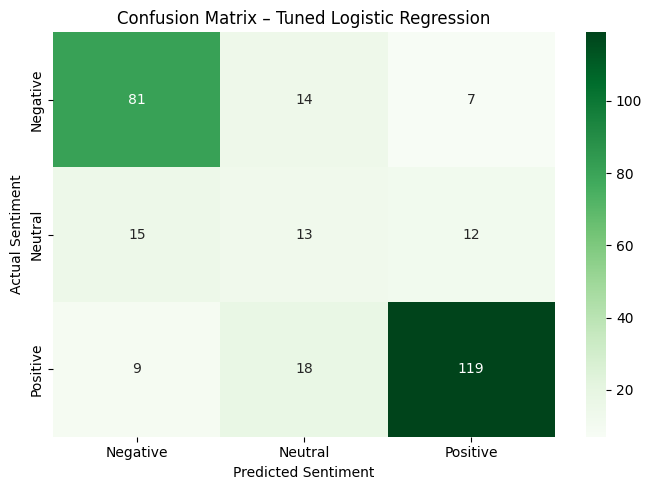

In [78]:
cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("Confusion Matrix – Tuned Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "visualizations",
        "tuned_model_confusion_matrix.png"
    ),
    dpi=300
)

plt.show()

In [79]:
comparison_results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test_tfidf)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7604,0.6538,0.6563,0.6543
1,Linear SVM,0.7708,0.6547,0.6450,0.6437
2,Random Forest,0.7743,0.7166,0.6100,0.5928
3,Multinomial Naive Bayes,0.7708,0.5242,0.5847,0.5486


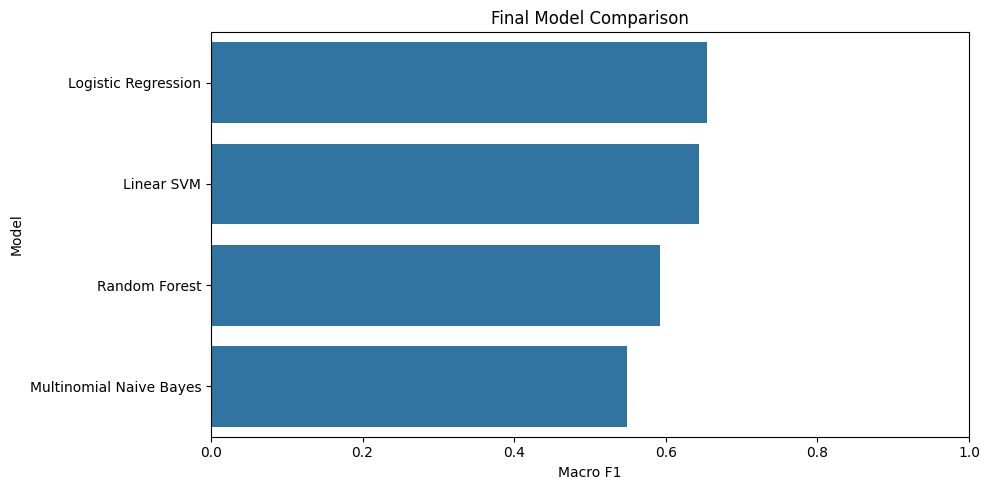

In [80]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_df,
    x="Macro F1",
    y="Model"
)

plt.title("Final Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_PATH,
        "visualizations",
        "final_model_comparison.png"
    ),
    dpi=300
)

plt.show()

In [81]:
from sklearn.pipeline import Pipeline
import joblib
import os

# Create final pipeline
final_model = Pipeline([
    ("tfidf", vectorizer),
    ("classifier", trained_models["Logistic Regression"])
])

# Save the complete pipeline
FINAL_MODEL_PATH = os.path.join(
    PROJECT_PATH,
    "models",
    "final_sentiment_model.pkl"
)

joblib.dump(final_model, FINAL_MODEL_PATH)

print("Final model saved successfully!")
print("Location:", FINAL_MODEL_PATH)

Final model saved successfully!
Location: /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/models/final_sentiment_model.pkl


In [82]:
loaded_model = joblib.load(FINAL_MODEL_PATH)

test_reviews = [
    "Excellent camera and amazing battery life.",
    "Very poor quality and disappointing performance.",
    "The phone is average."
]

predictions = loaded_model.predict(test_reviews)

for review, sentiment in zip(test_reviews, predictions):
    print("Review:", review)
    print("Sentiment:", sentiment)
    print("-" * 50)

Review: Excellent camera and amazing battery life.
Sentiment: Positive
--------------------------------------------------
Review: Very poor quality and disappointing performance.
Sentiment: Neutral
--------------------------------------------------
Review: The phone is average.
Sentiment: Neutral
--------------------------------------------------


In [83]:
%%writefile /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/app.py

import streamlit as st
import joblib
import os

st.set_page_config(
    page_title="Product Review Sentiment Analysis",
    page_icon="📱",
    layout="centered"
)

MODEL_PATH = os.path.join(
    os.path.dirname(__file__),
    "..",
    "models",
    "final_sentiment_model.pkl"
)

model = joblib.load(MODEL_PATH)

st.title("📱 Product Review Sentiment Analysis")

st.write(
    "Analyse customer reviews and identify "
    "whether the sentiment is Positive, Negative or Neutral."
)

review = st.text_area(
    "Enter your customer review:",
    placeholder="Example: The camera is excellent and battery life is amazing."
)

if st.button("Analyse Sentiment"):

    if review.strip():

        prediction = model.predict([review])[0]

        if prediction == "Positive":
            st.success("Positive Sentiment 😊")

        elif prediction == "Negative":
            st.error("Negative Sentiment 😞")

        else:
            st.info("Neutral Sentiment 😐")

    else:
        st.warning("Please enter a customer review.")

Writing /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/app.py


In [84]:
%%writefile /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/requirements.txt

streamlit
scikit-learn
joblib

Writing /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/requirements.txt


In [85]:
import os

DEPLOYMENT_PATH = os.path.join(PROJECT_PATH, "deployment")

print(os.listdir(DEPLOYMENT_PATH))

['app.py', 'requirements.txt']


In [86]:
import os
import sklearn

MODEL_FILE = os.path.join(
    PROJECT_PATH,
    "models",
    "final_sentiment_model.pkl"
)

print("Model exists:", os.path.exists(MODEL_FILE))

if os.path.exists(MODEL_FILE):
    size_mb = os.path.getsize(MODEL_FILE) / (1024 * 1024)
    print("Model size:", round(size_mb, 2), "MB")

print("Scikit-learn version:", sklearn.__version__)

Model exists: True
Model size: 0.3 MB
Scikit-learn version: 1.6.1


In [87]:
%%writefile /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/requirements.txt

streamlit
scikit-learn==1.6.1
joblib

Overwriting /content/drive/MyDrive/P719_NLP_Sentiment_Analysis/deployment/requirements.txt
